In [101]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import max_error, mean_absolute_error, mean_squared_error, r2_score

##### Datasets: House Prices Dataset (Multiple Linear Regression – Kaggle)

In [81]:
house_df = pd.read_csv("housing.csv")
house_df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


Tasks
1. Perform EDA on datasets.

2. Apply required data preprocessing steps:
    * Handling missing values
    * Feature encoding (if applicable)
    * Feature scaling
3. Build a Multiple Linear Regression model for the housing dataset.

4. Interpret regression coefficients in real-world terms.

5. Evaluate model using R², MSE, and residual analysis.

6. State and verify assumptions of linear regression.

EDA

In [82]:
house_df.shape

(20640, 10)

In [83]:
house_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [84]:
house_df.isna().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In California House Price, we can see that the dataset contains 20,640 rows and 10 column. We have only one categorical column "Ocean Proximity" and the rest has float datas. There are 207 null values in "total bedroom" column.

In [85]:
house_df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [87]:
house_df.housing_median_age.unique()

array([41., 21., 52., 42., 50., 40., 49., 48., 51., 43.,  2., 46., 26.,
       20., 17., 36., 19., 23., 38., 35., 10., 16., 27., 39., 31., 29.,
       22., 37., 28., 34., 32., 47., 44., 30., 18., 45., 33., 24., 15.,
       14., 13., 25.,  5., 12.,  6.,  8.,  9.,  7.,  3.,  4., 11.,  1.])

In [88]:
house_df.ocean_proximity.value_counts(normalize="True")

ocean_proximity
<1H OCEAN     0.442636
INLAND        0.317393
NEAR OCEAN    0.128779
NEAR BAY      0.110950
ISLAND        0.000242
Name: proportion, dtype: float64

In [89]:
house_df.groupby(by="ocean_proximity")["median_income"].agg(["mean", "max", "min"])

,mean,max,min
ocean_proximity,,,
<1H OCEAN,4.230682,15.0001,0.4999
INLAND,3.208996,15.0001,0.4999
ISLAND,2.744420,3.3906,2.1579
NEAR BAY,4.172885,15.0001,0.4999
NEAR OCEAN,4.005785,15.0001,0.5360


In [90]:
house_df.groupby(by="ocean_proximity")["median_house_value"].agg(["mean", "max", "min"])

,mean,max,min
ocean_proximity,,,
<1H OCEAN,240084.285464,500001.0,17500.0
INLAND,124805.392001,500001.0,14999.0
ISLAND,380440.000000,450000.0,287500.0
NEAR BAY,259212.311790,500001.0,22500.0
NEAR OCEAN,249433.977427,500001.0,22500.0


The least expensive house can be found in the Inland areas. In the Island, the house price range is narrower, however it has the least maximum price of 450,000 and the highest minimum price of 287,500. The highest price is 500,001 for all the other areas.

<Axes: xlabel='median_house_value', ylabel='Count'>

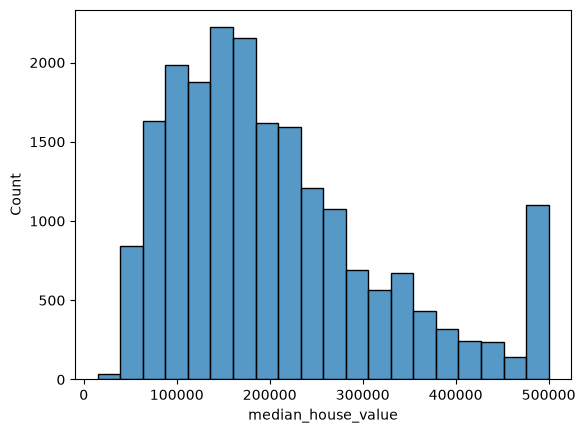

In [73]:
sns.histplot(house_df["median_house_value"], bins= 20)

<Axes: xlabel='median_income', ylabel='median_house_value'>

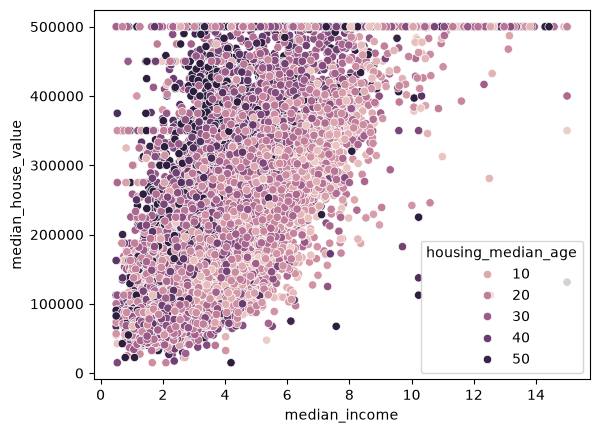

In [97]:
sns.scatterplot(house_df, x="median_income", y="median_house_value", hue="housing_median_age")

<Axes: >

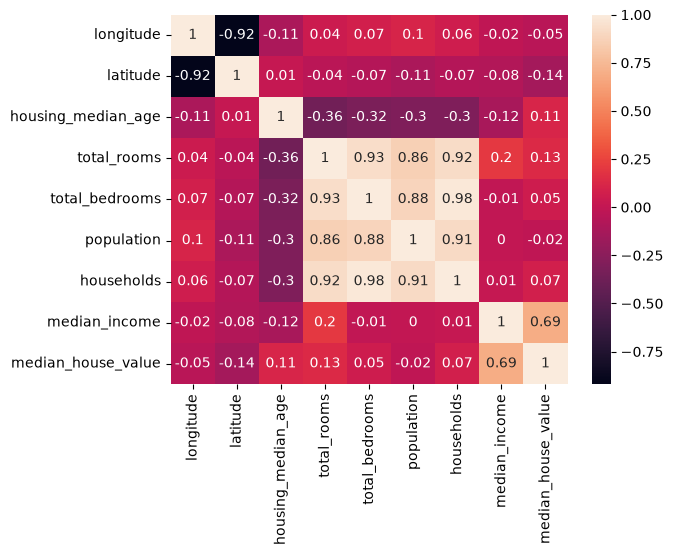

In [61]:
correlation = house_df.corr(numeric_only=True).round(2)
sns.heatmap(correlation, annot= True)

<Axes: xlabel='households', ylabel='total_rooms'>

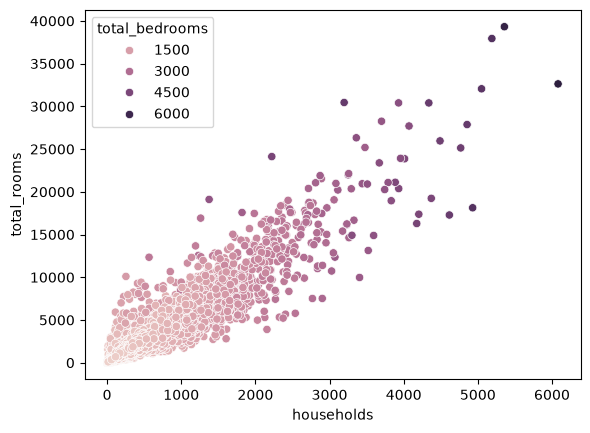

In [40]:
sns.scatterplot(house_df, x = "households", y= "total_rooms", hue= "total_bedrooms")

Handling missing values

The highest correlation that bedroom has is with total rooms and households. Since these do not provide proper data to fill null value, it has been considered more feasible to drop rows of missing values.

In [91]:
#Missing Values
house_df.dropna(inplace= True)

In [92]:
house_df["total_bedrooms"].isna().sum()

np.int64(0)

In [93]:
#Encoding - One Hot Encoding
house_df = pd.get_dummies(house_df,columns= ["ocean_proximity"])
house_df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,False,False,False,True,False
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,False,False,False,True,False
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,False,False,False,True,False
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,False,False,False,True,False
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,False,False,False,True,False


In [104]:
X= house_df.drop("median_house_value", axis = 1).to_numpy()
y = house_df[["median_house_value"]].to_numpy()

In [105]:
#Scaling
std_scaler = StandardScaler()
scaled_house_df = std_scaler.fit_transform(X)

In [106]:
lin_reg = LinearRegression()

In [107]:
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42)

In [108]:
lin_reg.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 13)","[[-27108.75,-25657.81, 1081.36,...,179383.93,-40501.86,-31102.97]]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[-2265004.32]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,13
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(12)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](13,)","[310659.48, 69084.82, 22167.57,..., 30.52, 1.93, 0. ]"


In [109]:
#Beta 0
lin_reg.intercept_

array([-2265004.31871641])

In [110]:
#Betas
lin_reg.coef_

array([[-2.71087463e+04, -2.56578075e+04,  1.08136421e+03,
        -6.32214552e+00,  1.03004042e+02, -3.64097514e+01,
         4.31427249e+01,  3.92770830e+04, -3.42694434e+04,
        -7.35096612e+04,  1.79383931e+05, -4.05018603e+04,
        -3.11029663e+04]])

In [111]:
SSE =  np.sum(np.power(y_train - lin_reg.predict(X_train), 2))
SSE

np.float64(76671095663934.3)

In [113]:
y_pred = lin_reg.predict(X_test)

In [114]:
max_error(y_test, y_pred)

409902.5013678777

In [116]:
mean_absolute_error(y_test, y_pred)

50413.433308101085

In [115]:
mean_squared_error(y_test, y_pred)

4802173538.604149

In [117]:
r2_score(y_test, y_pred)

0.6488402154432001

In [118]:
n,d = X_train.shape
r2_coeff = r2_score(y_test, y_pred)

In [119]:
adj_r2 = 1 - (1-r2_coeff) * ((n-1) / (n-d-1))
adj_r2

0.6485606981030557